---
title: "Transformers Explained: A Hands-On Deep Dive with Code and Visuals"
author: "Fabian"
date: "2025-02-12"
categories: [NLP]
format:
  html:
    code-fold: false
    toc: true
    echo: true
jupyter: python3
freeze: true
draft: true

---

Transformers are the foundation of modern AI models like GPT, BERT, and Claude. If you’ve used ChatGPT, you’ve already interacted with them in action. But what exactly makes Transformers so powerful?

This post is written for **new AI engineers**. We’ll start with intuition, then walk through **each building block step by step** using **PyTorch code, shapes, and diagrams**. You’ll also find **mini-experiments** you can run to really cement the concepts.

---

## 1. Why Transformers?

Before Transformers, we used Recurrent Neural Networks (RNNs) and LSTMs for sequence tasks. They processed words one at a time — like whispering around a circle. This was slow and struggled to remember context far away.

Transformers solve this with **self-attention**:

* Every word can directly “look” at every other word in the sequence.
* They process entire sequences **in parallel**, making training much faster.



/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_16787/4055122848.py:123: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from current font.
  plt.tight_layout()
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_16787/4055122848.py:123: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from current font.
  plt.tight_layout()
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_16787/4055122848.py:123: UserWarning: Glyph 128640 (\N{ROCKET}) missing from current font.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from current font.
  f

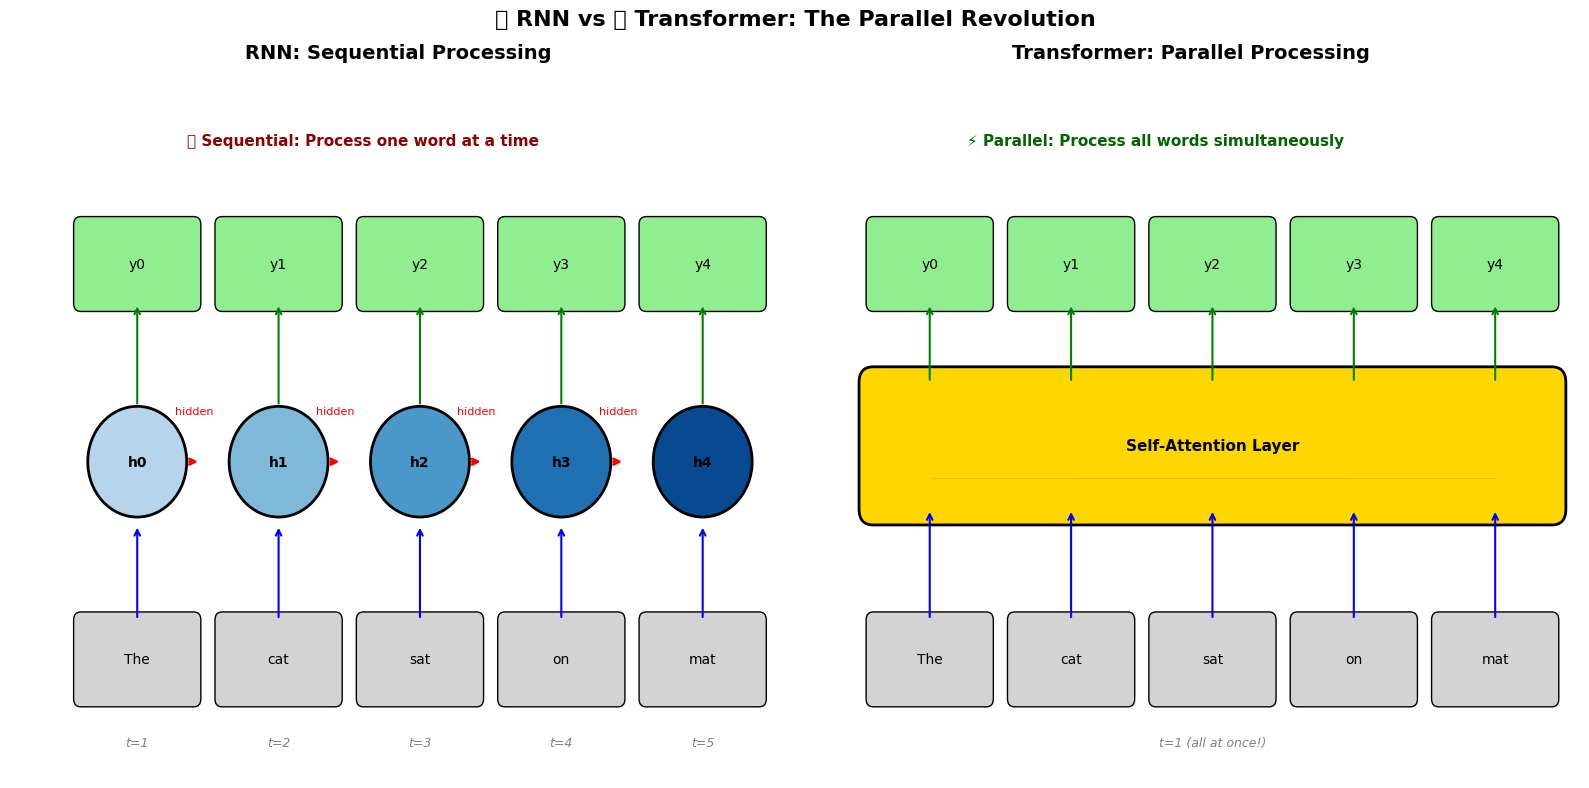


📊 Key Differences:
• RNN: Must wait for previous word → Slow training, hard to parallelize
• Transformer: All words processed at once → Fast training on GPUs
• RNN: Information degrades over long sequences
• Transformer: Direct connections between all positions


In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# Create comparison visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))

# RNN Processing (Sequential)
ax1.set_title('RNN: Sequential Processing', fontsize=14, fontweight='bold')
ax1.set_xlim(-0.5, 5)
ax1.set_ylim(-0.5, 4)
ax1.axis('off')

words = ["The", "cat", "sat", "on", "mat"]
colors = plt.cm.Blues(np.linspace(0.3, 0.9, len(words)))

# Draw RNN cells and connections
for i, word in enumerate(words):
    # Input word
    rect = FancyBboxPatch((i, 0), 0.8, 0.5,
                          boxstyle="round,pad=0.05",
                          facecolor='lightgray', edgecolor='black', linewidth=1)
    ax1.add_patch(rect)
    ax1.text(i+0.4, 0.25, word, ha='center', va='center', fontsize=10)
    
    # RNN cell
    circle = patches.Circle((i+0.4, 1.5), 0.35, 
                           facecolor=colors[i], edgecolor='black', linewidth=2)
    ax1.add_patch(circle)
    ax1.text(i+0.4, 1.5, f'h{i}', ha='center', va='center', fontsize=10, fontweight='bold')
    
    # Arrow from input to cell
    ax1.annotate('', xy=(i+0.4, 1.1), xytext=(i+0.4, 0.5),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='blue'))
    
    # Hidden state connection to next cell
    if i < len(words) - 1:
        ax1.annotate('', xy=(i+0.85, 1.5), xytext=(i+0.75, 1.5),
                    arrowprops=dict(arrowstyle='->', lw=2, color='red'))
        ax1.text(i+0.8, 1.8, 'hidden', fontsize=8, color='red', ha='center')
    
    # Output
    rect = FancyBboxPatch((i, 2.5), 0.8, 0.5,
                          boxstyle="round,pad=0.05",
                          facecolor='lightgreen', edgecolor='black', linewidth=1)
    ax1.add_patch(rect)
    ax1.text(i+0.4, 2.75, f'y{i}', ha='center', va='center', fontsize=10)
    
    # Arrow from cell to output
    ax1.annotate('', xy=(i+0.4, 2.5), xytext=(i+0.4, 1.85),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='green'))

# Add timing annotations
for i in range(len(words)):
    ax1.text(i+0.4, -0.3, f't={i+1}', ha='center', fontsize=9, style='italic', color='gray')

ax1.text(2, 3.5, '⏱️ Sequential: Process one word at a time', 
         ha='center', fontsize=11, fontweight='bold', color='darkred')

# Transformer Processing (Parallel)
ax2.set_title('Transformer: Parallel Processing', fontsize=14, fontweight='bold')
ax2.set_xlim(-0.5, 5)
ax2.set_ylim(-0.5, 4)
ax2.axis('off')

# Draw all inputs simultaneously
for i, word in enumerate(words):
    # Input word
    rect = FancyBboxPatch((i, 0), 0.8, 0.5,
                          boxstyle="round,pad=0.05",
                          facecolor='lightgray', edgecolor='black', linewidth=1)
    ax2.add_patch(rect)
    ax2.text(i+0.4, 0.25, word, ha='center', va='center', fontsize=10)

# Self-attention layer (all-to-all connections)
attention_rect = FancyBboxPatch((0, 1.2), 4.8, 0.8,
                               boxstyle="round,pad=0.1",
                               facecolor='gold', edgecolor='black', linewidth=2)
ax2.add_patch(attention_rect)
ax2.text(2.4, 1.6, 'Self-Attention Layer', ha='center', va='center', 
         fontsize=11, fontweight='bold')

# Draw attention connections (simplified)
for i in range(len(words)):
    # From input to attention
    ax2.annotate('', xy=(i+0.4, 1.2), xytext=(i+0.4, 0.5),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='blue'))
    
    # All-to-all connections within attention (sample)
    for j in range(len(words)):
        if i != j:
            alpha = 0.15
            ax2.plot([i+0.4, j+0.4], [1.4, 1.4], 'orange', alpha=alpha, lw=0.5)

# Output layer
for i, word in enumerate(words):
    rect = FancyBboxPatch((i, 2.5), 0.8, 0.5,
                          boxstyle="round,pad=0.05",
                          facecolor='lightgreen', edgecolor='black', linewidth=1)
    ax2.add_patch(rect)
    ax2.text(i+0.4, 2.75, f'y{i}', ha='center', va='center', fontsize=10)
    
    # From attention to output
    ax2.annotate('', xy=(i+0.4, 2.5), xytext=(i+0.4, 2.0),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='green'))

# Add timing annotation
ax2.text(2.4, -0.3, 't=1 (all at once!)', ha='center', fontsize=9, 
         style='italic', color='gray')

ax2.text(2, 3.5, '⚡ Parallel: Process all words simultaneously', 
         ha='center', fontsize=11, fontweight='bold', color='darkgreen')

# Add connection lines showing all-to-all attention
for i in range(len(words)):
    for j in range(len(words)):
        if abs(i-j) <= 2 and i != j:  # Show nearby connections more prominently
            ax2.plot([i+0.4, j+0.4], [1.55, 1.55], 'gold', alpha=0.3, lw=1)

plt.suptitle('🔄 RNN vs 🚀 Transformer: The Parallel Revolution', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📊 Key Differences:")
print("• RNN: Must wait for previous word → Slow training, hard to parallelize")
print("• Transformer: All words processed at once → Fast training on GPUs")
print("• RNN: Information degrades over long sequences")
print("• Transformer: Direct connections between all positions")

## 2. Step One: Tokens and Embeddings

Text is first converted to **tokens** (integers) and then mapped to **embeddings** (vectors).

📝 Example sentence: The cat sat
🔢 Token IDs: [1, 2, 3]
tokens              : (1, 3)
embeddings          : (1, 3, 8)


/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/1403277949.py:72: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from current font.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128260 (\N{ANTICLOCKWISE DOWNWARDS AND UPWARDS OPEN CIRCLE ARROWS}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


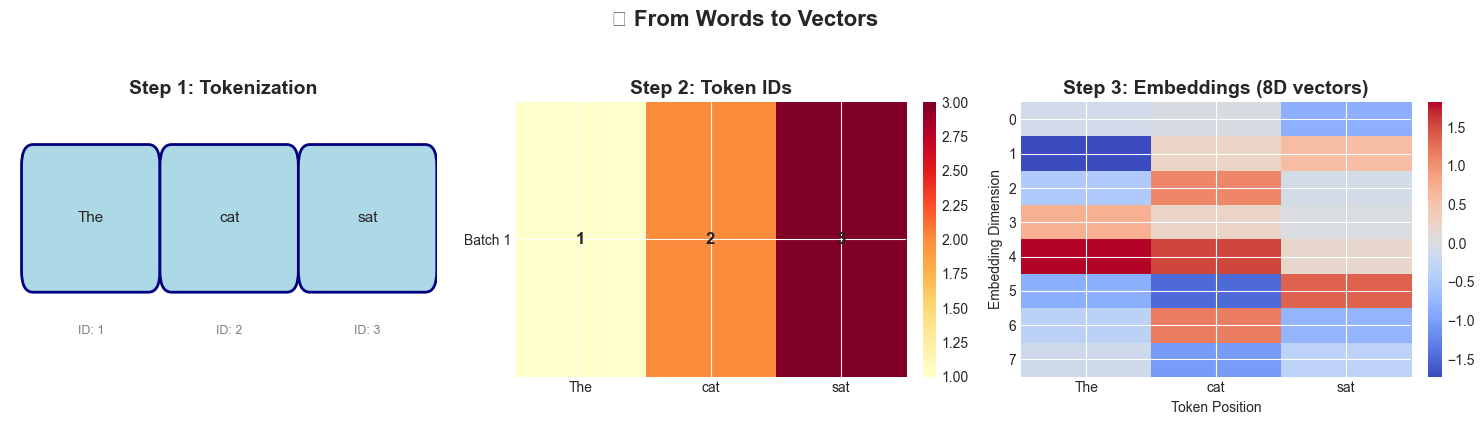


💡 Key Insight: Each word becomes an 8-dimensional vector that captures its meaning!


In [13]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle, FancyBboxPatch
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Set style for better visuals
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

def shape(name, x): 
    print(f"{name:20s}: {tuple(x.shape)}")

# Example sentence
sentence = "The cat sat"
vocab = {"<PAD>": 0, "The": 1, "cat": 2, "sat": 3, "on": 4, "mat": 5}
tokens = torch.tensor([[vocab[w] for w in sentence.split()]])  # (batch=1, seq=3)

# Create embedding layer
embedding = nn.Embedding(num_embeddings=len(vocab), embedding_dim=8)
x = embedding(tokens)

print("📝 Example sentence:", sentence)
print("🔢 Token IDs:", tokens.tolist()[0])
shape("tokens", tokens)     
shape("embeddings", x)      

# Visualize the transformation
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Tokens visualization
ax1.set_title("Step 1: Tokenization", fontsize=14, fontweight='bold')
for i, word in enumerate(sentence.split()):
    rect = FancyBboxPatch((i*1.2, 0), 1, 0.5, 
                          boxstyle="round,pad=0.1",
                          facecolor='lightblue', 
                          edgecolor='navy', linewidth=2)
    ax1.add_patch(rect)
    ax1.text(i*1.2+0.5, 0.25, word, ha='center', va='center', fontsize=11)
    ax1.text(i*1.2+0.5, -0.3, f"ID: {tokens[0, i]}", ha='center', fontsize=9, color='gray')
ax1.set_xlim(-0.2, 3.5)
ax1.set_ylim(-0.5, 0.8)
ax1.axis('off')

# Token IDs as matrix
ax2.set_title("Step 2: Token IDs", fontsize=14, fontweight='bold')
token_matrix = tokens.numpy()
im = ax2.imshow(token_matrix, cmap='YlOrRd', aspect='auto')
for i in range(token_matrix.shape[1]):
    ax2.text(i, 0, str(token_matrix[0, i]), ha='center', va='center', fontsize=12, fontweight='bold')
ax2.set_xticks(range(3))
ax2.set_xticklabels(sentence.split())
ax2.set_yticks([0])
ax2.set_yticklabels(['Batch 1'])
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

# Embedding visualization
ax3.set_title("Step 3: Embeddings (8D vectors)", fontsize=14, fontweight='bold')
embedding_matrix = x[0].detach().numpy()
im = ax3.imshow(embedding_matrix.T, cmap='coolwarm', aspect='auto')
ax3.set_xlabel("Token Position")
ax3.set_ylabel("Embedding Dimension")
ax3.set_xticks(range(3))
ax3.set_xticklabels(sentence.split())
ax3.set_yticks(range(8))
plt.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)

plt.suptitle("🔄 From Words to Vectors", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

print("\n💡 Key Insight: Each word becomes an 8-dimensional vector that captures its meaning!")

## 3. Step Two: Positional Encoding

Transformers don’t know word order by default. So we add **positional encodings**.

/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/2698661106.py:68: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from current font.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 127754 (\N{WATER WAVE}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


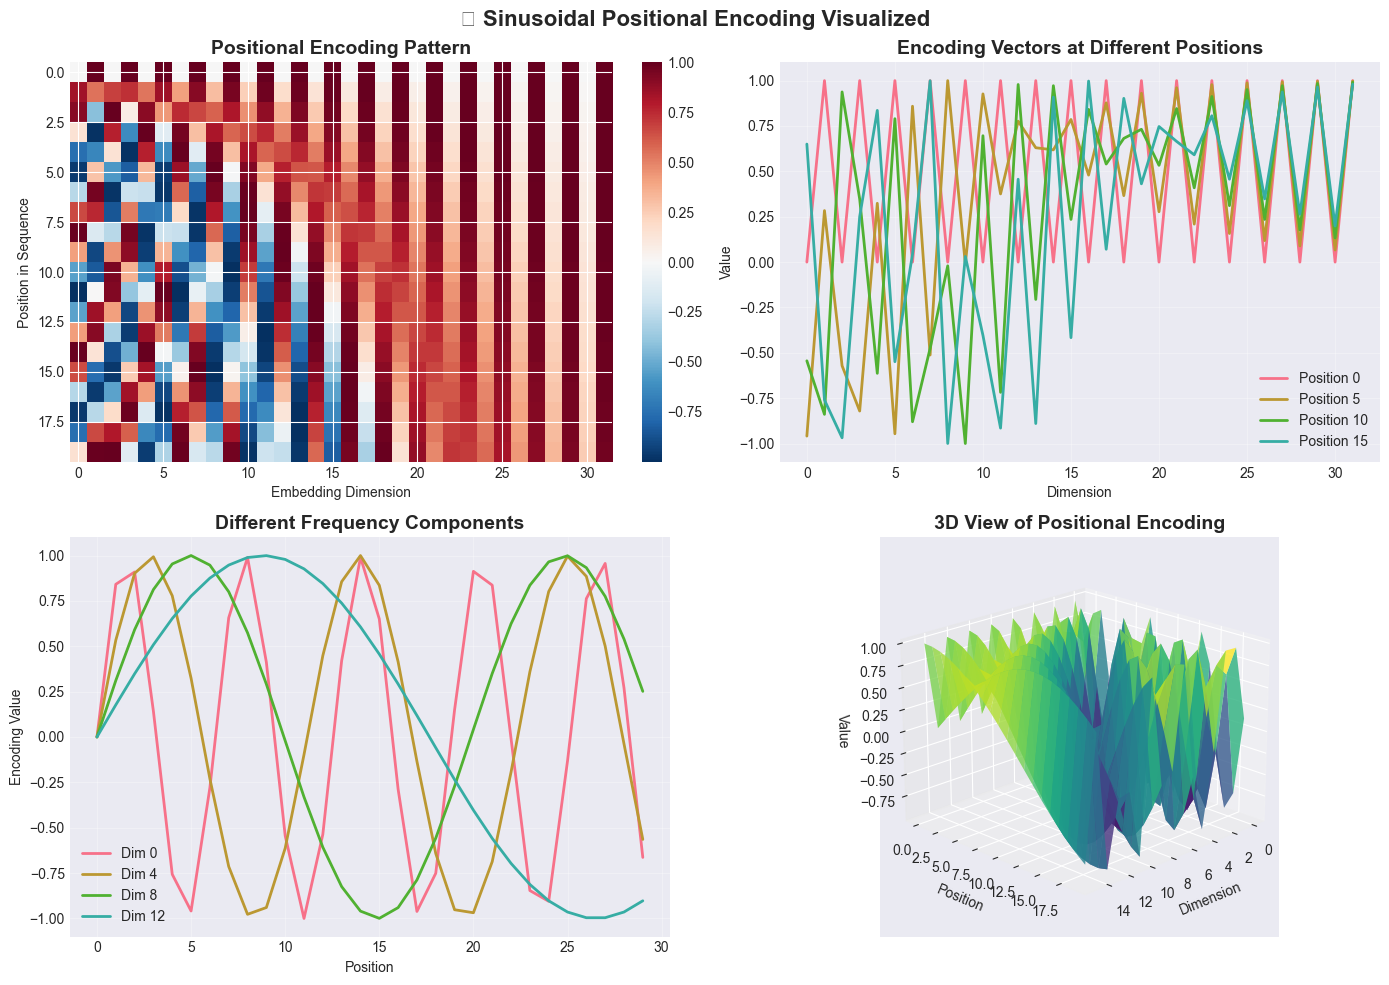


🎯 Why Sinusoidal?
• Each position gets a unique pattern
• Model can learn relative positions (pos[i+k] can be computed from pos[i])
• Works for sequences longer than training data!


In [14]:
import math

def positional_encoding(seq_len, dim):
    """Create sinusoidal positional encodings."""
    pe = torch.zeros(seq_len, dim)
    pos = torch.arange(0, seq_len).unsqueeze(1).float()
    
    # Create frequency bands
    div = torch.exp(torch.arange(0, dim, 2).float() * (-math.log(10000.0) / dim))
    
    # Apply sin to even indices
    pe[:, 0::2] = torch.sin(pos * div)
    # Apply cos to odd indices  
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

# Generate positional encodings
pe = positional_encoding(seq_len=50, dim=64)

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Full positional encoding matrix
ax = axes[0, 0]
im = ax.imshow(pe[:20, :32], cmap="RdBu_r", aspect='auto')
ax.set_title("Positional Encoding Pattern", fontsize=14, fontweight='bold')
ax.set_xlabel("Embedding Dimension")
ax.set_ylabel("Position in Sequence")
plt.colorbar(im, ax=ax, fraction=0.046)

# 2. Single position encoding
ax = axes[0, 1]
positions_to_show = [0, 5, 10, 15]
for pos in positions_to_show:
    ax.plot(pe[pos, :32], label=f'Position {pos}', linewidth=2)
ax.set_title("Encoding Vectors at Different Positions", fontsize=14, fontweight='bold')
ax.set_xlabel("Dimension")
ax.set_ylabel("Value")
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Frequency visualization
ax = axes[1, 0]
for dim in [0, 4, 8, 12]:
    ax.plot(pe[:30, dim], label=f'Dim {dim}', linewidth=2)
ax.set_title("Different Frequency Components", fontsize=14, fontweight='bold')
ax.set_xlabel("Position")
ax.set_ylabel("Encoding Value")
ax.legend()
ax.grid(True, alpha=0.3)

# 4. 3D visualization of encoding space
ax = axes[1, 1]
ax.remove()
ax = fig.add_subplot(2, 2, 4, projection='3d')
positions = np.arange(20)
dimensions = np.arange(16)
X, Y = np.meshgrid(dimensions, positions)
Z = pe[:20, :16].numpy()
surf = ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8)
ax.set_title("3D View of Positional Encoding", fontsize=14, fontweight='bold')
ax.set_xlabel("Dimension")
ax.set_ylabel("Position")
ax.set_zlabel("Value")
ax.view_init(elev=20, azim=45)

plt.suptitle("🌊 Sinusoidal Positional Encoding Visualized", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🎯 Why Sinusoidal?")
print("• Each position gets a unique pattern")
print("• Model can learn relative positions (pos[i+k] can be computed from pos[i])")
print("• Works for sequences longer than training data!")

Produces a striped heatmap: every row is a position, every column is a feature.

### Learned Encoding

Often we just **learn embeddings for positions**:

In [15]:
class LearnedPositionalEncoding(nn.Module):
    def __init__(self, max_len: int, dim: int):
        super().__init__()
        self.pos = nn.Embedding(max_len, dim)

    def forward(self, x):  # x: (B, T, C)
        B, T, C = x.shape
        idx = torch.arange(T, device=x.device)
        return x + self.pos(idx)[None, :, :]

## 4. Step Three: Self-Attention

This is the **core magic**. Each token produces:

* **Query (Q)**: What am I looking for?
* **Key (K)**: What do I contain?
* **Value (V)**: What info do I carry?

Attention compares queries to keys to decide “who should I listen to?”

/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/4089171138.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 129504 (\N{BRAIN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


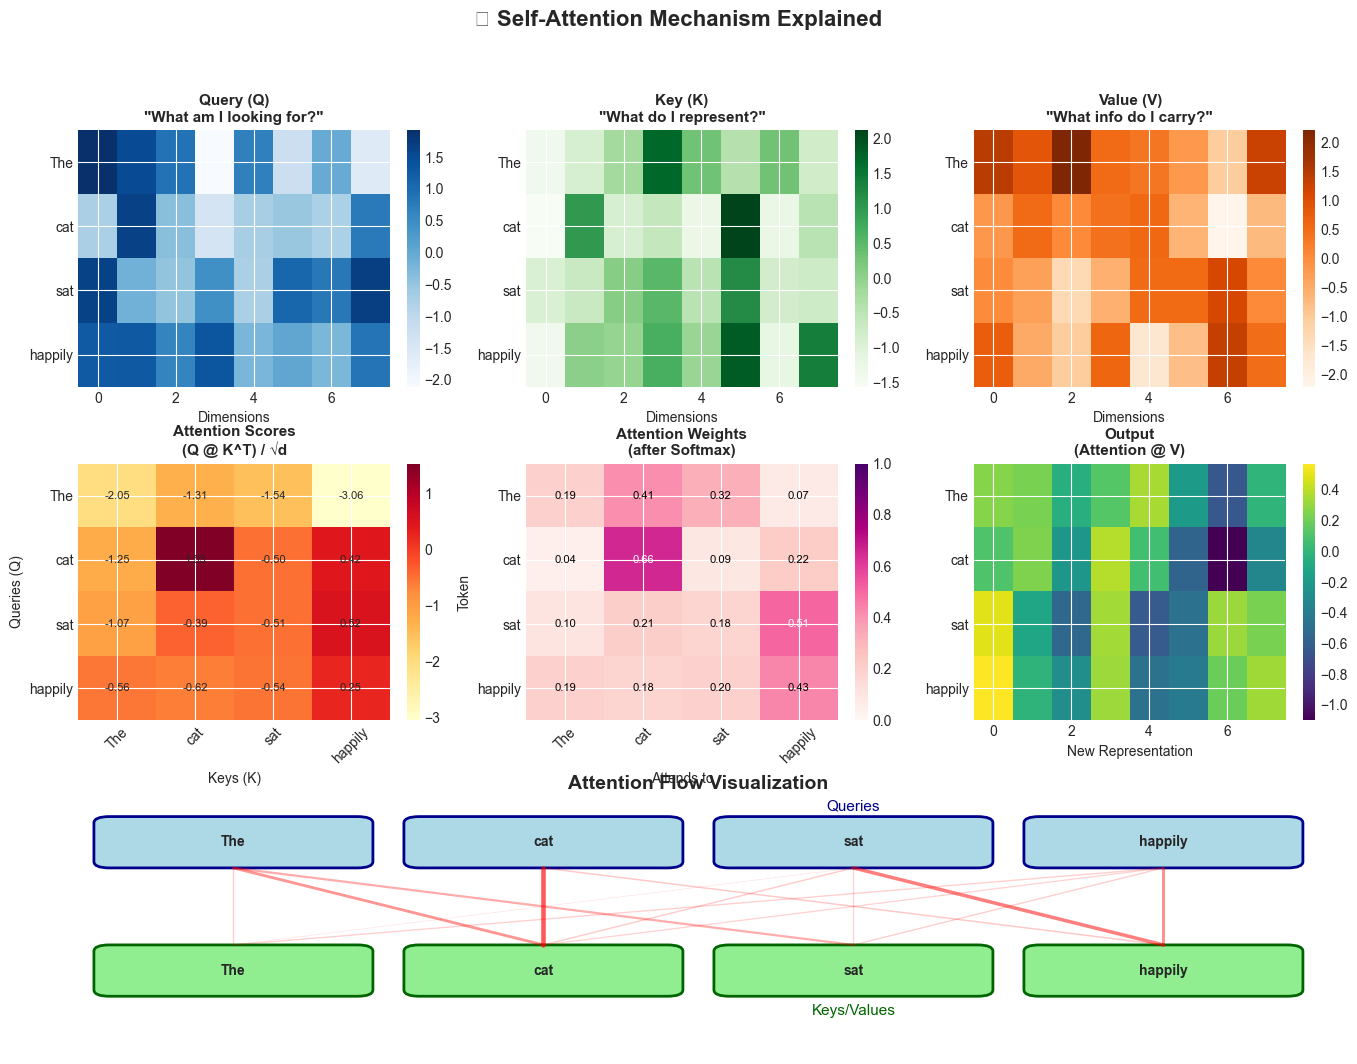


🔍 What's happening here?
1. Each word creates a Query: 'What information am I looking for?'
2. Each word creates a Key: 'What information do I represent?'
3. Each word creates a Value: 'What actual information do I carry?'
4. Attention scores = How well each Query matches each Key
5. Softmax converts scores to probabilities (weights)
6. Output = Weighted sum of Values based on attention weights


In [16]:
def scaled_dot_attention(Q, K, V, mask=None):
    """
    Compute scaled dot-product attention.
    Q, K, V: (batch, seq_len, dim)
    """
    # Step 1: Compute attention scores
    scores = Q @ K.transpose(-2, -1) / (Q.size(-1) ** 0.5)
    
    # Step 2: Apply mask if provided
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)
    
    # Step 3: Apply softmax to get attention weights
    weights = torch.softmax(scores, dim=-1)
    
    # Step 4: Apply attention weights to values
    output = weights @ V
    
    return output, weights

# Create example with meaningful words
words = ["The", "cat", "sat", "happily"]
seq_len = len(words)
d_model = 8

# Set seed for reproducibility
torch.manual_seed(42)

# Create Q, K, V matrices
Q = torch.randn(1, seq_len, d_model)
K = torch.randn(1, seq_len, d_model)
V = torch.randn(1, seq_len, d_model)

# Compute attention
output, attn_weights = scaled_dot_attention(Q, K, V)

# Visualize the attention mechanism step by step
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# Step 1: Q, K, V matrices
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])

for ax, matrix, name, color in zip([ax1, ax2, ax3], 
                                   [Q[0], K[0], V[0]], 
                                   ['Query (Q)', 'Key (K)', 'Value (V)'],
                                   ['Blues', 'Greens', 'Oranges']):
    im = ax.imshow(matrix.detach().numpy(), cmap=color, aspect='auto')
    ax.set_title(f'{name}\n"What am I looking for?"' if 'Q' in name else 
                 f'{name}\n"What do I represent?"' if 'K' in name else
                 f'{name}\n"What info do I carry?"', fontsize=11, fontweight='bold')
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(words)
    ax.set_xlabel("Dimensions")
    plt.colorbar(im, ax=ax, fraction=0.046)

# Step 2: Attention scores (Q @ K^T)
ax4 = fig.add_subplot(gs[1, 0])
scores = (Q @ K.transpose(-2, -1))[0] / (d_model ** 0.5)
im = ax4.imshow(scores.detach().numpy(), cmap='YlOrRd', aspect='auto')
ax4.set_title('Attention Scores\n(Q @ K^T) / √d', fontsize=11, fontweight='bold')
ax4.set_xticks(range(seq_len))
ax4.set_xticklabels(words, rotation=45)
ax4.set_yticks(range(seq_len))
ax4.set_yticklabels(words)
ax4.set_xlabel("Keys (K)")
ax4.set_ylabel("Queries (Q)")
plt.colorbar(im, ax=ax4, fraction=0.046)

# Annotate scores
for i in range(seq_len):
    for j in range(seq_len):
        ax4.text(j, i, f'{scores[i, j]:.2f}', ha='center', va='center', fontsize=8)

# Step 3: Attention weights (after softmax)
ax5 = fig.add_subplot(gs[1, 1])
im = ax5.imshow(attn_weights[0].detach().numpy(), cmap='RdPu', aspect='auto', vmin=0, vmax=1)
ax5.set_title('Attention Weights\n(after Softmax)', fontsize=11, fontweight='bold')
ax5.set_xticks(range(seq_len))
ax5.set_xticklabels(words, rotation=45)
ax5.set_yticks(range(seq_len))
ax5.set_yticklabels(words)
ax5.set_xlabel("Attends to")
ax5.set_ylabel("Token")
plt.colorbar(im, ax=ax5, fraction=0.046)

# Annotate weights
for i in range(seq_len):
    for j in range(seq_len):
        weight = attn_weights[0, i, j].item()
        ax5.text(j, i, f'{weight:.2f}', ha='center', va='center', 
                fontsize=8, color='white' if weight > 0.5 else 'black')

# Step 4: Output (Attention @ V)
ax6 = fig.add_subplot(gs[1, 2])
im = ax6.imshow(output[0].detach().numpy(), cmap='viridis', aspect='auto')
ax6.set_title('Output\n(Attention @ V)', fontsize=11, fontweight='bold')
ax6.set_yticks(range(seq_len))
ax6.set_yticklabels(words)
ax6.set_xlabel("New Representation")
plt.colorbar(im, ax=ax6, fraction=0.046)

# Step 5: Attention flow diagram
ax7 = fig.add_subplot(gs[2, :])
ax7.set_title('Attention Flow Visualization', fontsize=14, fontweight='bold')
ax7.set_xlim(-0.5, seq_len - 0.5)
ax7.set_ylim(-0.5, 1.5)

# Draw tokens
for i, word in enumerate(words):
    # Query tokens (top)
    rect = FancyBboxPatch((i-0.4, 1), 0.8, 0.3, 
                          boxstyle="round,pad=0.05",
                          facecolor='lightblue', edgecolor='darkblue', linewidth=2)
    ax7.add_patch(rect)
    ax7.text(i, 1.15, word, ha='center', va='center', fontsize=10, fontweight='bold')
    
    # Key/Value tokens (bottom)
    rect = FancyBboxPatch((i-0.4, 0), 0.8, 0.3,
                          boxstyle="round,pad=0.05",
                          facecolor='lightgreen', edgecolor='darkgreen', linewidth=2)
    ax7.add_patch(rect)
    ax7.text(i, 0.15, word, ha='center', va='center', fontsize=10, fontweight='bold')

# Draw attention connections
for i in range(seq_len):
    for j in range(seq_len):
        weight = attn_weights[0, i, j].item()
        if weight > 0.1:  # Only show significant connections
            ax7.plot([i, j], [0.95, 0.35], 'r-', alpha=weight, linewidth=weight*5)

ax7.text(seq_len/2, 1.4, "Queries", ha='center', fontsize=11, color='darkblue')
ax7.text(seq_len/2, -0.2, "Keys/Values", ha='center', fontsize=11, color='darkgreen')
ax7.axis('off')

plt.suptitle('🧠 Self-Attention Mechanism Explained', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n🔍 What's happening here?")
print("1. Each word creates a Query: 'What information am I looking for?'")
print("2. Each word creates a Key: 'What information do I represent?'")
print("3. Each word creates a Value: 'What actual information do I carry?'")
print("4. Attention scores = How well each Query matches each Key")
print("5. Softmax converts scores to probabilities (weights)")
print("6. Output = Weighted sum of Values based on attention weights")


## 5. Step Four: Multi-Head Attention

Instead of one attention map, Transformers use **multiple heads**.

* One head might focus on syntax.
* Another might focus on long-range meaning.

In [17]:
attn = nn.MultiheadAttention(embed_dim=8, num_heads=2, batch_first=True)
x = torch.rand(1, 4, 8)
out, weights = attn(x, x, x)
print(out.shape)  # (1, 4, 8)

torch.Size([1, 4, 8])


## 6. Step Five: Feed-Forward Networks

After attention, each token’s vector runs through a **tiny MLP**:

In [18]:
ffn = nn.Sequential(
    nn.Linear(8, 16),
    nn.ReLU(),
    nn.Linear(16, 8)
)

x = torch.rand(4, 8)
out = ffn(x)

# Adds nonlinearity, mixing features across dimensions.

## 7. Step Six: Residual Connections + Normalization

Deep models are hard to train. Transformers stabilize learning with:

* **Residuals**: Add input back → avoids vanishing gradients.
* **LayerNorm**: Normalizes across features.

In [19]:
layernorm = nn.LayerNorm(8)
x = torch.rand(4, 8)
out = ffn(x)
out = layernorm(out + x)

## 8. Step Seven: The Transformer Block

Now we combine it all:

In [20]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim*4),
            nn.ReLU(),
            nn.Linear(dim*4, dim)
        )
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
    
    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        ffn_out = self.ffn(x)
        x = self.norm2(x + ffn_out)
        return x

## The Complete Transformer Architecture

Now let's visualize how all these components connect together:

/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/3540959989.py:128: UserWarning: Glyph 127959 (\N{BUILDING CONSTRUCTION}) missing from current font.
  plt.tight_layout()
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/3540959989.py:128: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 127959 (\N{BUILDING CONSTRUCTION}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


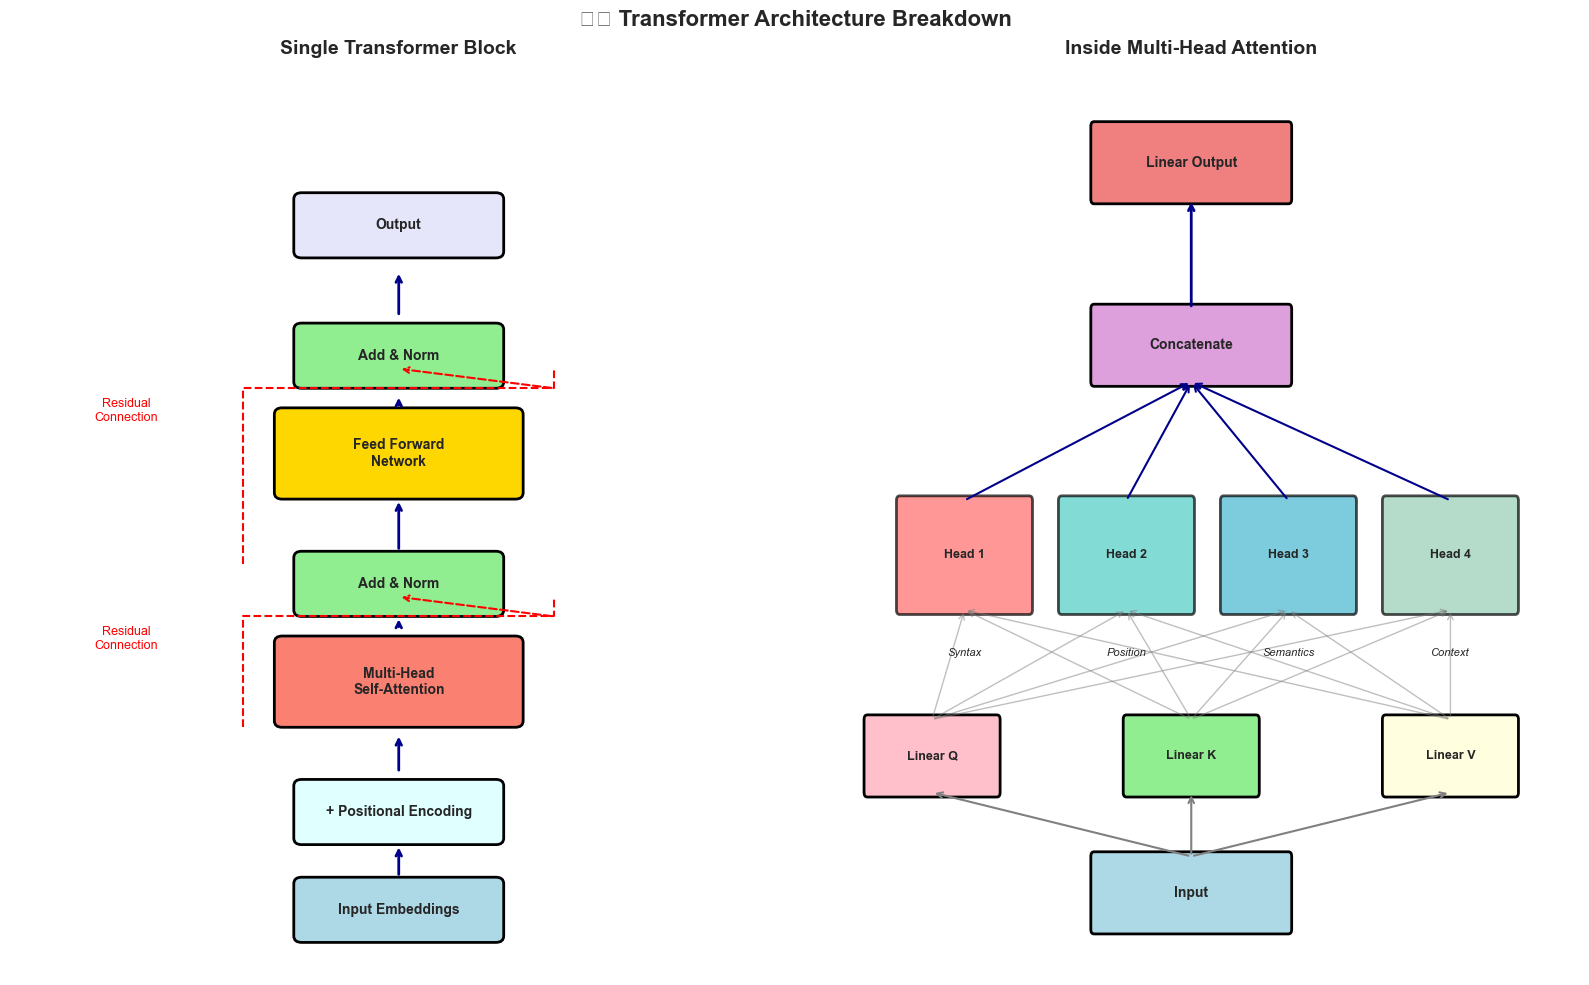


📊 Architecture Key Points:
• Left: Complete transformer block with residual connections
• Right: How multi-head attention splits computation across specialized heads
• Each head learns different types of relationships (syntax, semantics, etc.)
• Residual connections (red) help with gradient flow in deep networks


In [21]:
# Create a comprehensive transformer architecture diagram
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.lines as mlines

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 10))

# Left: Single Transformer Block
ax1.set_title('Single Transformer Block', fontsize=14, fontweight='bold')
ax1.set_xlim(0, 10)
ax1.set_ylim(0, 14)
ax1.axis('off')

# Component boxes with better styling
components = [
    (5, 1, 'Input Embeddings', 'lightblue'),
    (5, 2.5, '+ Positional Encoding', 'lightcyan'),
    (5, 4.5, 'Multi-Head\nSelf-Attention', 'salmon'),
    (5, 6, 'Add & Norm', 'lightgreen'),
    (5, 8, 'Feed Forward\nNetwork', 'gold'),
    (5, 9.5, 'Add & Norm', 'lightgreen'),
    (5, 11.5, 'Output', 'lavender')
]

for x, y, text, color in components:
    if 'Multi-Head' in text or 'Feed Forward' in text:
        width, height = 3, 1.2
    else:
        width, height = 2.5, 0.8
    
    rect = FancyBboxPatch((x - width/2, y - height/2), width, height,
                          boxstyle="round,pad=0.1",
                          facecolor=color, edgecolor='black', linewidth=2)
    ax1.add_patch(rect)
    ax1.text(x, y, text, ha='center', va='center', fontsize=10, fontweight='bold')

# Arrows showing data flow
arrow_props = dict(arrowstyle='->', lw=2, color='darkblue')
ax1.annotate('', xy=(5, 2), xytext=(5, 1.5), arrowprops=arrow_props)
ax1.annotate('', xy=(5, 3.7), xytext=(5, 3.1), arrowprops=arrow_props)
ax1.annotate('', xy=(5, 5.5), xytext=(5, 5.3), arrowprops=arrow_props)
ax1.annotate('', xy=(5, 7.3), xytext=(5, 6.5), arrowprops=arrow_props)
ax1.annotate('', xy=(5, 8.9), xytext=(5, 8.7), arrowprops=arrow_props)
ax1.annotate('', xy=(5, 10.8), xytext=(5, 10.1), arrowprops=arrow_props)

# Residual connections
residual_props = dict(arrowstyle='->', lw=1.5, color='red', linestyle='--')
# First residual (around attention)
ax1.plot([3, 3, 7, 7], [3.8, 5.5, 5.5, 5.8], 'r--', lw=1.5)
ax1.annotate('', xy=(5, 5.8), xytext=(7, 5.5), arrowprops=residual_props)
# Second residual (around FFN)
ax1.plot([3, 3, 7, 7], [6.3, 9, 9, 9.3], 'r--', lw=1.5)
ax1.annotate('', xy=(5, 9.3), xytext=(7, 9), arrowprops=residual_props)

# Add labels
ax1.text(1.5, 5, 'Residual\nConnection', fontsize=9, color='red', ha='center')
ax1.text(1.5, 8.5, 'Residual\nConnection', fontsize=9, color='red', ha='center')

# Right: Multi-Head Attention Details
ax2.set_title('Inside Multi-Head Attention', fontsize=14, fontweight='bold')
ax2.set_xlim(0, 12)
ax2.set_ylim(0, 10)
ax2.axis('off')

# Input
input_rect = FancyBboxPatch((4.5, 0.5), 3, 0.8,
                           boxstyle="round,pad=0.05",
                           facecolor='lightblue', edgecolor='black', linewidth=2)
ax2.add_patch(input_rect)
ax2.text(6, 0.9, 'Input', ha='center', va='center', fontsize=10, fontweight='bold')

# Linear projections for Q, K, V
for i, (label, color, x) in enumerate([('Linear Q', 'pink', 2), 
                                        ('Linear K', 'lightgreen', 6), 
                                        ('Linear V', 'lightyellow', 10)]):
    rect = FancyBboxPatch((x-1, 2), 2, 0.8,
                          boxstyle="round,pad=0.05",
                          facecolor=color, edgecolor='black', linewidth=2)
    ax2.add_patch(rect)
    ax2.text(x, 2.4, label, ha='center', va='center', fontsize=9, fontweight='bold')
    ax2.annotate('', xy=(x, 2), xytext=(6, 1.3), 
                arrowprops=dict(arrowstyle='->', lw=1.5, color='gray'))

# Attention heads
head_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']
for i in range(4):
    x = 1.5 + i * 2.5
    rect = FancyBboxPatch((x, 4), 2, 1.2,
                          boxstyle="round,pad=0.05",
                          facecolor=head_colors[i], edgecolor='black', linewidth=2, alpha=0.7)
    ax2.add_patch(rect)
    ax2.text(x+1, 4.6, f'Head {i+1}', ha='center', va='center', fontsize=9, fontweight='bold')
    
    # Arrows from Q, K, V to heads
    for proj_x in [2, 6, 10]:
        ax2.annotate('', xy=(x+1, 4), xytext=(proj_x, 2.8),
                    arrowprops=dict(arrowstyle='->', lw=1, color='gray', alpha=0.5))

# Concatenation
concat_rect = FancyBboxPatch((4.5, 6.5), 3, 0.8,
                            boxstyle="round,pad=0.05",
                            facecolor='plum', edgecolor='black', linewidth=2)
ax2.add_patch(concat_rect)
ax2.text(6, 6.9, 'Concatenate', ha='center', va='center', fontsize=10, fontweight='bold')

# Arrows from heads to concatenation
for i in range(4):
    x = 2.5 + i * 2.5
    ax2.annotate('', xy=(6, 6.5), xytext=(x, 5.2),
                arrowprops=dict(arrowstyle='->', lw=1.5, color='darkblue'))

# Linear output projection
output_rect = FancyBboxPatch((4.5, 8.5), 3, 0.8,
                            boxstyle="round,pad=0.05",
                            facecolor='lightcoral', edgecolor='black', linewidth=2)
ax2.add_patch(output_rect)
ax2.text(6, 8.9, 'Linear Output', ha='center', va='center', fontsize=10, fontweight='bold')
ax2.annotate('', xy=(6, 8.5), xytext=(6, 7.3),
            arrowprops=dict(arrowstyle='->', lw=2, color='darkblue'))

# Add head specialization annotations
ax2.text(2.5, 3.5, 'Syntax', fontsize=8, style='italic', ha='center')
ax2.text(5, 3.5, 'Position', fontsize=8, style='italic', ha='center')
ax2.text(7.5, 3.5, 'Semantics', fontsize=8, style='italic', ha='center')
ax2.text(10, 3.5, 'Context', fontsize=8, style='italic', ha='center')

plt.suptitle('🏗️ Transformer Architecture Breakdown', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📊 Architecture Key Points:")
print("• Left: Complete transformer block with residual connections")
print("• Right: How multi-head attention splits computation across specialized heads")
print("• Each head learns different types of relationships (syntax, semantics, etc.)")
print("• Residual connections (red) help with gradient flow in deep networks")

## 9. Masks: Padding vs Causal

Transformers use **masks** to control attention:

* **Padding mask**: ignore `<pad>` tokens.
* **Causal mask**: prevent looking ahead (needed for GPT).

/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/3002744150.py:132: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from current font.
  plt.tight_layout()
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/3002744150.py:132: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from current font.
  plt.tight_layout()
/var/folders/nq/y2lyg7p15txfm5ksrw6f90340000gn/T/ipykernel_10760/3002744150.py:132: UserWarning: Glyph 127917 (\N{PERFORMING ARTS}) missing from current font.
  plt.tight_layout()
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/fabianlanderos/miniforge3/envs/quarto/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/fabianlanderos/miniforge3/envs/quar

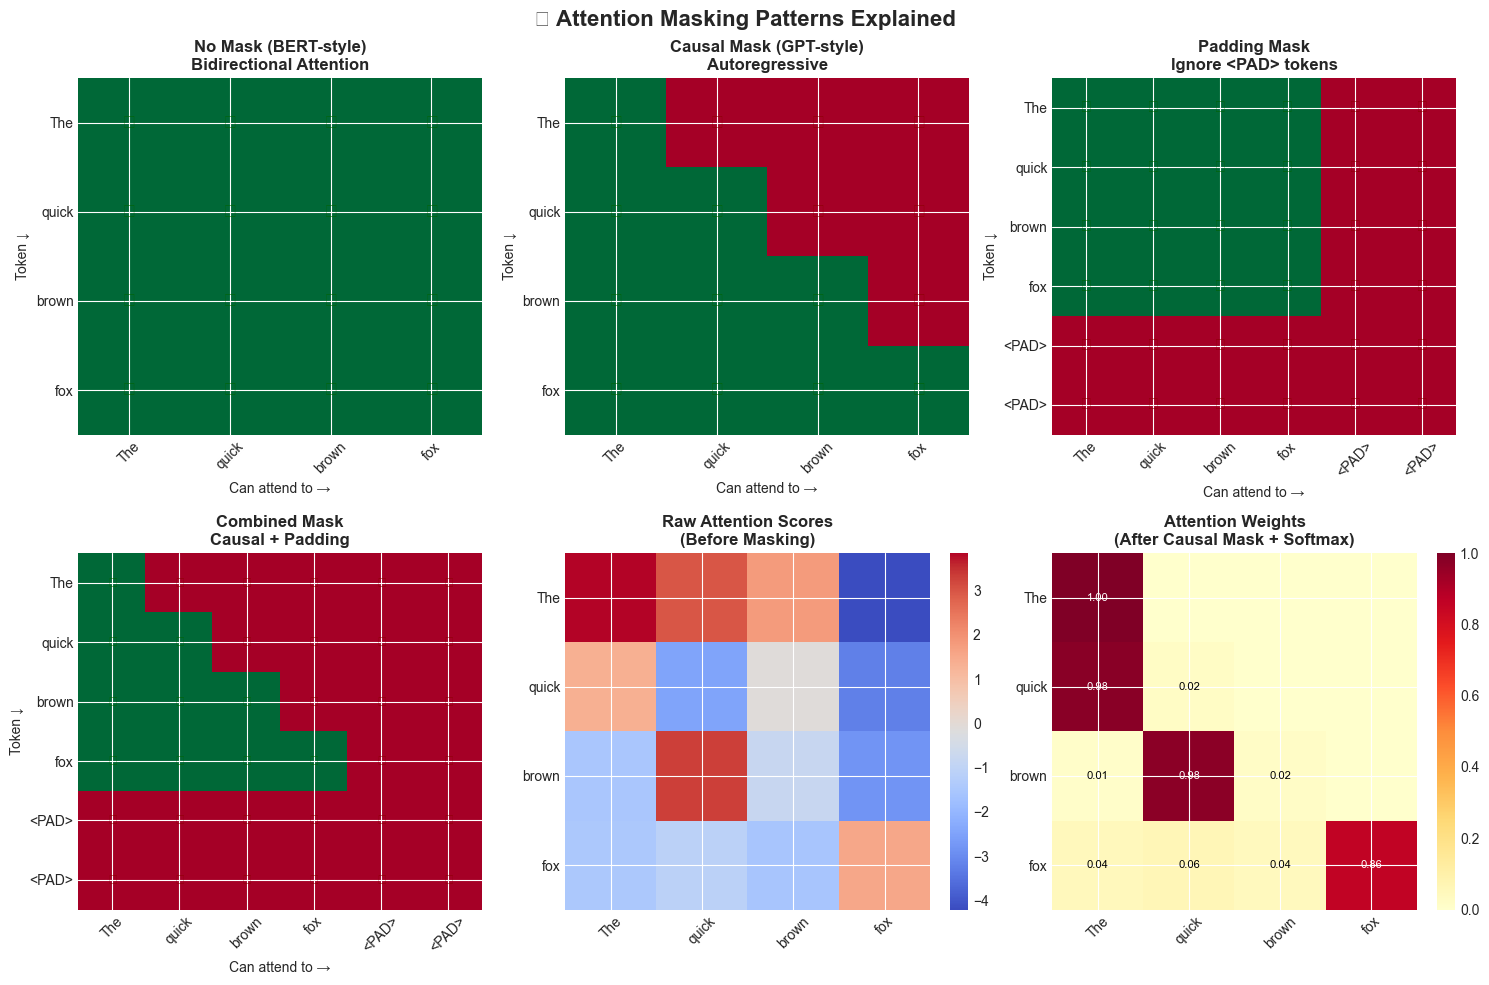


🔑 Key Insights:
• BERT uses no mask → can see all words (good for understanding)
• GPT uses causal mask → can only see past words (good for generation)
• Padding masks prevent attending to padding tokens
• Masks work by setting unwanted scores to -∞ before softmax


In [22]:
# Interactive masking demonstration
import torch
import torch.nn.functional as F

def visualize_masks(sentence="The cat sat on mat"):
    """Visualize different types of attention masks."""
    words = sentence.split()
    seq_len = len(words)
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # 1. No mask (bidirectional attention)
    no_mask = torch.ones(seq_len, seq_len)
    ax = axes[0, 0]
    im = ax.imshow(no_mask, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_title('No Mask (BERT-style)\nBidirectional Attention', fontsize=12, fontweight='bold')
    ax.set_xticks(range(seq_len))
    ax.set_xticklabels(words, rotation=45)
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(words)
    ax.set_xlabel("Can attend to →")
    ax.set_ylabel("Token ↓")
    
    # Add annotations
    for i in range(seq_len):
        for j in range(seq_len):
            ax.text(j, i, '✓', ha='center', va='center', fontsize=14, color='darkgreen')
    
    # 2. Causal mask (autoregressive)
    causal_mask = torch.tril(torch.ones(seq_len, seq_len))
    ax = axes[0, 1]
    im = ax.imshow(causal_mask, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_title('Causal Mask (GPT-style)\nAutoregressive', fontsize=12, fontweight='bold')
    ax.set_xticks(range(seq_len))
    ax.set_xticklabels(words, rotation=45)
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(words)
    ax.set_xlabel("Can attend to →")
    ax.set_ylabel("Token ↓")
    
    for i in range(seq_len):
        for j in range(seq_len):
            if causal_mask[i, j] == 1:
                ax.text(j, i, '✓', ha='center', va='center', fontsize=14, color='darkgreen')
            else:
                ax.text(j, i, '✗', ha='center', va='center', fontsize=14, color='darkred')
    
    # 3. Padding mask
    # Simulate a padded sequence
    padded_words = words + ['<PAD>', '<PAD>']
    padded_len = len(padded_words)
    padding_mask = torch.ones(padded_len, padded_len)
    padding_mask[seq_len:, :] = 0  # Mask out padding tokens as queries
    padding_mask[:, seq_len:] = 0  # Mask out padding tokens as keys
    
    ax = axes[0, 2]
    im = ax.imshow(padding_mask, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_title('Padding Mask\nIgnore <PAD> tokens', fontsize=12, fontweight='bold')
    ax.set_xticks(range(padded_len))
    ax.set_xticklabels(padded_words, rotation=45)
    ax.set_yticks(range(padded_len))
    ax.set_yticklabels(padded_words)
    ax.set_xlabel("Can attend to →")
    ax.set_ylabel("Token ↓")
    
    for i in range(padded_len):
        for j in range(padded_len):
            if padding_mask[i, j] == 1:
                ax.text(j, i, '✓', ha='center', va='center', fontsize=12, color='darkgreen')
            else:
                ax.text(j, i, '✗', ha='center', va='center', fontsize=12, color='darkred')
    
    # 4. Combined causal + padding mask
    combined_mask = torch.tril(torch.ones(padded_len, padded_len))
    combined_mask[seq_len:, :] = 0
    combined_mask[:, seq_len:] = 0
    
    ax = axes[1, 0]
    im = ax.imshow(combined_mask, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
    ax.set_title('Combined Mask\nCausal + Padding', fontsize=12, fontweight='bold')
    ax.set_xticks(range(padded_len))
    ax.set_xticklabels(padded_words, rotation=45)
    ax.set_yticks(range(padded_len))
    ax.set_yticklabels(padded_words)
    ax.set_xlabel("Can attend to →")
    ax.set_ylabel("Token ↓")
    
    for i in range(padded_len):
        for j in range(padded_len):
            if combined_mask[i, j] == 1:
                ax.text(j, i, '✓', ha='center', va='center', fontsize=10, color='darkgreen')
            else:
                ax.text(j, i, '✗', ha='center', va='center', fontsize=10, color='darkred')
    
    # 5. Attention scores with mask applied
    torch.manual_seed(42)
    scores = torch.randn(seq_len, seq_len) * 2
    
    ax = axes[1, 1]
    im = ax.imshow(scores.numpy(), cmap='coolwarm', aspect='auto')
    ax.set_title('Raw Attention Scores\n(Before Masking)', fontsize=12, fontweight='bold')
    ax.set_xticks(range(seq_len))
    ax.set_xticklabels(words, rotation=45)
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(words)
    plt.colorbar(im, ax=ax, fraction=0.046)
    
    # 6. Masked attention weights
    masked_scores = scores.clone()
    mask = torch.tril(torch.ones(seq_len, seq_len))
    masked_scores = masked_scores.masked_fill(mask == 0, -1e9)
    attention_weights = F.softmax(masked_scores, dim=-1)
    
    ax = axes[1, 2]
    im = ax.imshow(attention_weights.numpy(), cmap='YlOrRd', vmin=0, vmax=1, aspect='auto')
    ax.set_title('Attention Weights\n(After Causal Mask + Softmax)', fontsize=12, fontweight='bold')
    ax.set_xticks(range(seq_len))
    ax.set_xticklabels(words, rotation=45)
    ax.set_yticks(range(seq_len))
    ax.set_yticklabels(words)
    plt.colorbar(im, ax=ax, fraction=0.046)
    
    # Annotate with values
    for i in range(seq_len):
        for j in range(seq_len):
            if mask[i, j] == 1:
                val = attention_weights[i, j].item()
                ax.text(j, i, f'{val:.2f}', ha='center', va='center', 
                       fontsize=8, color='white' if val > 0.5 else 'black')
    
    plt.suptitle('🎭 Attention Masking Patterns Explained', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\n🔑 Key Insights:")
    print("• BERT uses no mask → can see all words (good for understanding)")
    print("• GPT uses causal mask → can only see past words (good for generation)")
    print("• Padding masks prevent attending to padding tokens")
    print("• Masks work by setting unwanted scores to -∞ before softmax")

# Run the visualization
visualize_masks("The quick brown fox")

## 10. Tiny Transformer (From Scratch)

Here’s a minimal GPT-like model:

```python
class TinyGPT(nn.Module):
    def __init__(self, vocab_size, dim=64, num_heads=4, depth=2, max_len=128):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, dim)
        self.pos = LearnedPositionalEncoding(max_len, dim)
        self.blocks = nn.ModuleList([TransformerBlock(dim, num_heads) for _ in range(depth)])
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)

    def forward(self, idx):
        x = self.tok(idx)
        x = self.pos(x)
        for blk in self.blocks:
            x = blk(x)
        return self.lm_head(x)  # (B, T, V)

🤖 Model initialized with 105,856 parameters
📚 Vocabulary size: 29 characters
📝 Training text length: 146 characters

🚀 Starting training...

Step   0 | Loss: 3.3840
Step  50 | Loss: 2.6482
Step 100 | Loss: 1.9852
Step 150 | Loss: 1.8036
Step 200 | Loss: 1.5836
Step 250 | Loss: 1.2130

✅ Training complete!

🎨 Generating text...

Generated: Hellorers forerer mere fuereweeque ss er oh se s s s se oe s s lerer asere erer fo orer s fqo s arfoderer


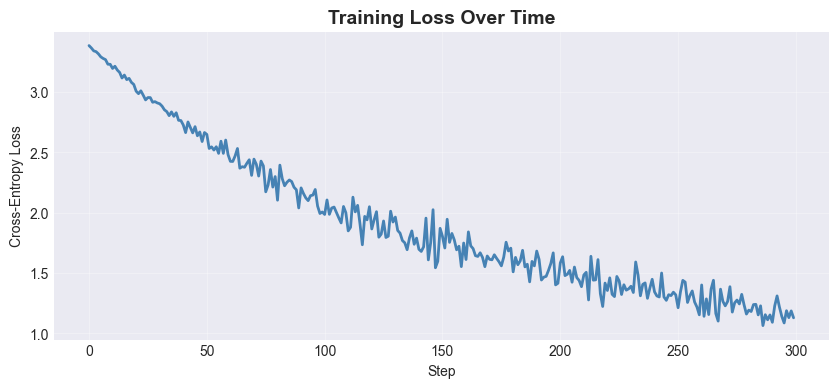


💡 What happened here?
• We trained a tiny GPT on character-level text
• The model learned patterns in just 300 steps
• It can now generate text character by character!
• Try adjusting temperature: lower = more focused, higher = more creative


In [23]:
# Complete working example: Character-level GPT
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

class TinyGPT(nn.Module):
    """A minimal GPT for character-level text generation."""
    
    def __init__(self, vocab_size, dim=64, num_heads=4, num_layers=2, max_len=128):
        super().__init__()
        self.dim = dim
        self.max_len = max_len
        
        # Token and position embeddings
        self.token_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(max_len, dim)
        
        # Transformer blocks
        self.blocks = nn.ModuleList([
            TransformerBlock(dim, num_heads) for _ in range(num_layers)
        ])
        
        # Final layer norm and output projection
        self.ln_f = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)
        
        # Initialize weights
        self.apply(self._init_weights)
    
    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            module.weight.data.normal_(mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                module.bias.data.zero_()
    
    def forward(self, idx, targets=None):
        B, T = idx.shape
        
        # Token + positional embeddings
        tok_emb = self.token_emb(idx)  # (B, T, C)
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device).unsqueeze(0)  # (1, T)
        pos_emb = self.pos_emb(pos)  # (1, T, C)
        x = tok_emb + pos_emb
        
        # Apply transformer blocks
        for block in self.blocks:
            x = block(x)
        
        # Final layer norm and output projection
        x = self.ln_f(x)
        logits = self.lm_head(x)  # (B, T, vocab_size)
        
        # Calculate loss if targets provided
        loss = None
        if targets is not None:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        
        return logits, loss
    
    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        """Generate text autoregressively."""
        for _ in range(max_new_tokens):
            # Crop context to max_len
            idx_cond = idx[:, -self.max_len:]
            
            # Get predictions
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature  # Focus on last token
            
            # Sample from distribution
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            
            # Append to sequence
            idx = torch.cat((idx, idx_next), dim=1)
        
        return idx

# Create a simple dataset
text = """Hello world! This is a simple transformer.
It learns patterns in text character by character.
Transformers are powerful models for sequence tasks."""

# Build vocabulary
chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}  # string to integer
itos = {i: ch for i, ch in enumerate(chars)}  # integer to string

# Encode and decode functions
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

# Prepare data
data = torch.tensor(encode(text), dtype=torch.long)

# Create training examples
block_size = 32

def get_batch(data, batch_size=4):
    """Generate a batch of training examples."""
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

# Initialize model
model = TinyGPT(
    vocab_size=vocab_size,
    dim=64,
    num_heads=4,
    num_layers=2,
    max_len=block_size
)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
print(f"🤖 Model initialized with {total_params:,} parameters")
print(f"📚 Vocabulary size: {vocab_size} characters")
print(f"📝 Training text length: {len(text)} characters\n")

# Training setup
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)
data = data.to(device)

# Training loop
print("🚀 Starting training...\n")
losses = []

for step in range(300):
    # Get batch
    xb, yb = get_batch(data, batch_size=8)
    xb, yb = xb.to(device), yb.to(device)
    
    # Forward pass
    logits, loss = model(xb, targets=yb)
    
    # Backward pass
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    losses.append(loss.item())
    
    # Print progress
    if step % 50 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")

print("\n✅ Training complete!\n")

# Generate some text
print("🎨 Generating text...\n")
model.eval()
context = torch.tensor(encode("Hello"), dtype=torch.long, device=device).unsqueeze(0)
generated = model.generate(context, max_new_tokens=100, temperature=0.8)
print("Generated:", decode(generated[0].tolist()))

# Plot training loss
plt.figure(figsize=(10, 4))
plt.plot(losses, color='steelblue', linewidth=2)
plt.title('Training Loss Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Step')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, alpha=0.3)
plt.show()

print("\n💡 What happened here?")
print("• We trained a tiny GPT on character-level text")
print("• The model learned patterns in just 300 steps")
print("• It can now generate text character by character!")
print("• Try adjusting temperature: lower = more focused, higher = more creative")

## 11. Experiments to Try

Now that you understand transformers, here are some experiments:

### Quick Experiments:
1. **Change the number of attention heads** - See how it affects learning
2. **Vary the temperature** in generation - Notice how it changes creativity
3. **Try different mask patterns** - Understand their effects
4. **Visualize attention weights** during training - Watch patterns emerge

### Advanced Projects:
1. **Build a mini-BERT** for classification
2. **Create a translation model** with encoder-decoder
3. **Fine-tune on your own text** - Make it write like you!
4. **Implement different position encodings** - RoPE, ALiBi, etc.

## Key Takeaways

🎯 **You've learned:**
- How text becomes vectors through embeddings
- Why positional encoding matters
- The magic of self-attention (Q, K, V)
- How multi-head attention creates specialized features
- The role of masks in controlling information flow
- How to build and train your own transformer!

🚀 **Next Steps:**
- Try implementing variants like BERT or T5
- Explore modern improvements: Flash Attention, RoPE, etc.
- Scale up to larger models and datasets
- Read the original ["Attention Is All You Need"](https://arxiv.org/abs/1706.03762) paper

---

*Remember: The best way to understand transformers is to build them yourself. Start small, experiment often, and gradually increase complexity. Happy coding!*